# Codelab: Latihan SKLearn Support Vector Regression (SVR)

Notebook ini berisi implementasi **Support Vector Regression (SVR)** menggunakan library `scikit-learn` untuk memprediksi besaran gaji (`Salary`) berdasarkan lama pengalaman kerja seseorang (`YearsExperience`).

> **Catatan Penggunaan di Google Colab:** Pastikan berkas `Salary_Data.csv` sudah diunggah ke direktori kerja Google Colaboratory sebelum menjalankan sel kode di bawah ini.

## 1. Mengimpor Library dan Membaca Dataset
Pada langkah pertama, kita mengimpor library `pandas` dan membaca berkas `Salary_Data.csv` ke dalam bentuk **DataFrame**.

In [1]:
# Mengimpor library pandas untuk manipulasi dan analisis data tabular (DataFrame)
import pandas as pd

# Membaca berkas dataset 'Salary_Data.csv' dan mengubahnya menjadi objek DataFrame Pandas
data = pd.read_csv('Salary_Data.csv')

## 2. Memeriksa Struktur Dataset dan Missing Value
Gunakan fungsi `.info()` untuk memeriksa jumlah baris, tipe data setiap kolom, serta memastikan tidak ada nilai yang hilang (*missing value*).

In [2]:
# Menampilkan informasi ringkas DataFrame:
# - Jumlah entri/baris (30 baris, indeks 0 sampai 29)
# - Jumlah data non-null pada setiap kolom untuk mengecek missing value
# - Tipe data setiap kolom (float64)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 608.0 bytes


## 3. Melihat Sampel Data Teratas
Gunakan fungsi `.head()` untuk menampilkan 5 baris pertama dari dataset agar kita dapat memahami format nilai pada kolom `YearsExperience` dan `Salary`.

In [3]:
# Menampilkan 5 baris pertama dari dataset sebagai pratinjau struktur data
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## 4. Memisahkan Atribut (Fitur) dan Label serta Mengubah Bentuk Array
Ketika hanya terdapat **satu atribut** pada DataFrame, bentuk datanya masih berupa array 1 dimensi (`1D`). Model pada library `scikit-learn` mewajibkan input fitur berbentuk array 2 dimensi (`2D`), sehingga kita perlu mengubah bentuknya menggunakan library `numpy` (`np.newaxis`).

In [4]:
# Mengimpor library NumPy untuk operasi array numerik dan pengubahan dimensi
import numpy as np

# Memisahkan atribut/fitur (X) dan label/target prediksi (y)
X = data['YearsExperience']  # Fitur: lama pengalaman kerja (tahun)
y = data['Salary']           # Label: besaran gaji yang akan diprediksi

# Mengubah atribut X dari Pandas Series (1D) menjadi array NumPy 2D berukuran (30, 1)
# Penambahan sumbu baru (np.newaxis) diperlukan agar sesuai dengan standar input model SKLearn
X = np.array(X)
X = X[:, np.newaxis]

## 5. Membangun dan Melatih Model Support Vector Regression (SVR)
Selanjutnya, kita membuat objek model `SVR` dengan parameter `C = 1000`, `gamma = 0.05`, dan `kernel = 'rbf'`, lalu melatih model tersebut pada data menggunakan fungsi `.fit()`.

In [5]:
# Mengimpor kelas SVR (Support Vector Regression) dari modul svm pada library scikit-learn
from sklearn.svm import SVR

# Membangun objek model SVR dengan konfigurasi hyperparameter:
# - C=1000       : parameter regularisasi yang menentukan besar penalti terhadap error
# - gamma=0.05   : koefisien kernel RBF yang mengatur jangkauan pengaruh tiap sampel data
# - kernel='rbf' : menggunakan kernel Radial Basis Function untuk memetakan pola non-linear
model = SVR(C=1000, gamma=0.05, kernel='rbf')

# Melatih (fitting) model SVR menggunakan data atribut X dan label aktual y
model.fit(X, y)

SVR(C=1000, gamma=0.05)

## 6. Memvisualisasikan Hasil Prediksi Model
Kita menggunakan `matplotlib.pyplot` untuk membandingkan sebaran titik data aktual (`scatter`) dengan kurva hasil prediksi dari model SVR (`plot`).

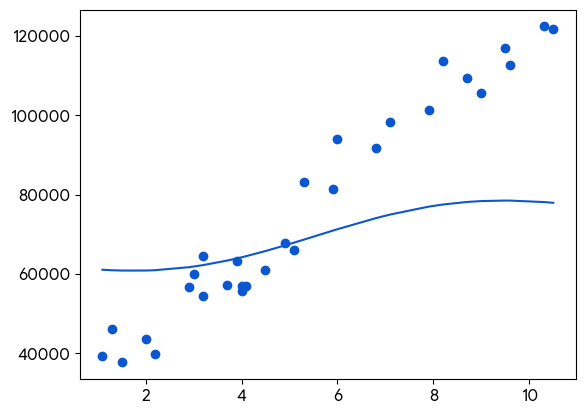

In [6]:
# Mengimpor modul pyplot dari library Matplotlib untuk visualisasi grafik
import matplotlib.pyplot as plt

# Membuat scatter plot untuk menampilkan titik-titik data aktual (YearsExperience vs Salary)
plt.scatter(X, y)

# Membuat garis kurva hasil prediksi model SVR berdasarkan input X
plt.plot(X, model.predict(X))

## Kesimpulan Evaluasi Visual
Hasil visualisasi menunjukkan bahwa model SVR dengan parameter awal (`C=1000`, `gamma=0.05`, `kernel='rbf'`) **belum mampu menyesuaikan terhadap pola kenaikan data dengan baik** (*underfitting*). Hal ini terjadi karena skala nilai `Salary` berada pada kisaran puluhan ribu hingga ratusan ribu, sehingga nilai `C=1000` masih terlalu kecil untuk menarik kurva mendekati data aktual.

Pada tahap pengembangan berikutnya, performa model dapat ditingkatkan secara signifikan menggunakan teknik **Grid Search** (`GridSearchCV`) untuk mencari kombinasi hyperparameter terbaik.